In [1]:
import numpy as np
from matplotlib import pyplot as plt

%config InlineBackend.figure_format = 'retina'

import camb 
from camb import initialpower, model
from scipy.signal import find_peaks

In [2]:
np.random.randint(10)

3

In [3]:
#FREQ BINS (random distribution)
#one per ten
#total 285 bins (is that doable...?) 
#adjust if necessary for computer lol 
freqstart = 200
freqend = 3000
freqbins = [freqstart+2]
binsize = 10

curr_start = freqstart + binsize
curr_end = freqstart+ 2*binsize

while curr_end <= freqend:
    inc = np.random.randint(10)
    freqbins.append(curr_start + inc)
    curr_end += binsize
    curr_start += binsize

In [4]:
len(freqbins)

280

In [5]:
#VALUES TO HOLD FIXED, from https://arxiv.org/pdf/2602.13523
h0 = 0.674
mnu=0.06
omk=0
tau=0.054
ns=0.965
lmax=3000

In [6]:
#actual values 
omL_actual = 0.685
ombh2_actual = 0.02237
omch2_actual = 0.1200

In [7]:
#given params for omch2, omb, omL, get data needed for desired graph
def get_data(omnuh2=0.0006448993754203254, omch2=None, omL=None, ombh2=None, calc='equal', verbose=False):
    
    #if calc is none, then just calculate based on omch2 value
    #if calc is equal, then set equal 
    #omc + omb = 1 - omnu - omk - omL

    #get omch2 and ombh2
    if calc=='equal':
        #set values equal
        omM = 1 - omnuh2/h0**2 - omk - omL
        omc = omM/2
        omb = omM/2
        omch2 = omc*h0**2
        ombh2 = omc*h0**2

    elif calc=='b':
        #make omb greater by 1/3
        omM = 1 - omnuh2/h0**2 - omk - omL
        omc = omM/3
        omb = omM/3 * 2
        ombh2 = omb*h0**2
        omch2 = omc*h0**2

    elif calc=='c':
        #make omc greater
        omM = 1 - omnuh2/h0**2 - omk - omL
        omc = omM/3 * 2
        omb = omM/3
        ombh2 = omb*h0**2
        omch2 = omc*h0**2

    elif type(calc) is int or type(calc) is float:
        #ratio between omc and omb
        omM = 1 - omnuh2/h0**2 - omk - omL
        omb = omM / (calc+1)
        omc = omb*calc
        ombh2 = omb*h0**2
        omch2 = omc*h0**2

    #confirm
    if verbose:
        print('omc=', round(omc, 4), 'omb=', round(omb, 4))
        print('balance', round(omc + omb, 4), round(1 - omnuh2/h0**2 - omk - omL, 4))
        
    #set up model params
    pars = camb.set_params(
        H0=h0*100,
        ombh2=ombh2,
        omch2=omch2,
        mnu=mnu,
        omk=omk,
        tau=tau,
        ns=ns,
        lmax=3000)

    #calculate
    results = camb.get_results(pars)
    
    #get power spectra
    powers = results.get_cmb_power_spectra(pars, CMB_unit="muK")
    #let's only care about total TT...
    totCL = powers['total']
    ls = np.arange(totCL.shape[0]) #xvals

    return ls, totCL[:,0]

In [8]:
def bin_data(ls, data):
    #take data @ centers of bins
    binned = []
    for bin in freqbins:
        ind = np.where(ls == bin)
        dat = data[ind][0]
        binned.append(dat)

    return binned

In [9]:
def limit_bins(binned, dat, bin_lim = len(freqbins)):

    #limit to given number of bins, distributed around peaks

    if bin_lim >= len(freqbins):
        return np.arange(len(freqbins))

    #first, find peaks from data 
    peaks, _ = find_peaks(dat)
    #limit peaks to range
    peaks = [x for x in peaks if x > freqstart and x < freqend]
   # print(peaks)

    #find bins closest to peaks 
    peak_bins = []
    for peak in peaks:
        found = False
        i=0
        while not found and i < len(freqbins):
            bin_start = freqbins[i]-binsize/2
            bin_end = freqbins[i]+binsize/2
            if bin_start <= peak and peak < bin_end:
                found = True
                peak_bins.append(i)
            i+=1

    bins_used = len(peak_bins)
    
    #add bins around each peak
    bins_left = bin_lim - bins_used 
    bins_per_peakside = bins_left // (len(peak_bins)*2)

    bins_wanted = []
    for b in peak_bins: 
        bins_wanted.append(b)
        for i in range(bins_per_peakside):
            if b-(i+1) >=0:
                bins_wanted.append(b-(i+1))
            if b+(i+1) < len(freqbins):
                bins_wanted.append(b+(i+1))

    bins_wanted = list(set(bins_wanted))

    #add in any remaining bins around peaks
    i=bins_per_peakside
    peak_ind = 0
    side = True
    while len(bins_wanted) < bin_lim:
        
        mult = (-1)**side
        b = peak_bins[peak_ind]
        #print('adding', i+1, 'around peak at freq', freqbins[peak_bins[peak_ind]], 'attempting', freqbins[b+(i+1)*mult])
        # print(i, peak_ind, side, b)
        # print('trying', b+(i*mult))
        if b+(i*mult) >= 0 and b+(i)*mult < len(freqbins) and b+(i*mult) not in bins_wanted:
            bins_wanted.append(b+(i*mult))
            # print ("added", b+(i*mult))

        side = not side
        if side:
            peak_ind = (peak_ind+1) % len(peak_bins)
            if peak_ind == 0:
                i+=1

    bins_wanted = list(set(bins_wanted))

    #turn into xvals and datavals 

    xvals = [freqbins[x] for x in bins_wanted]
    wanted_data = [binned[x] for x in bins_wanted]

    return xvals, wanted_data
    

In [10]:
def convert_to_ampfreq(xvals, data, mode='linear', datamax=None):
    #xvals convert directly to hertz
    #convert intensity to gain btwn 0 and 1? play around with this in audio...
    if mode == 'linear': 
        if datamax==None:
            datamax = max(data) #if not given universal maximum, just set by individual data (calc later) 
        amp = data/datamax

    if mode == 'log':
        amp = np.log(data)
        if datamax is None:
            datamax = max(amp)
        else:
            datamax = np.log(datamax)
        amp = amp/datamax

    freq = xvals
    return freq, amp

# TESTING

In [11]:
#first, make power spectra
xvals = []
datas = []

#different settings for omLambda
omLvals = [0.1, 0.35, 0.685, 0.8, 0.89]

In [12]:
ls, dat = get_data(omL=0.1, omch2=0.12, calc='equal', verbose=False)

In [13]:
#next, get binned data (limited to desired range)
binned = bin_data(ls, dat)

In [14]:
#next, limit by number of bins
lim_x, lim_dat = limit_bins(binned, dat, bin_lim=100)

In [15]:
#finally, convert to frequency and amplitude (log or linear)
freq, amplin = convert_to_ampfreq(lim_x, lim_dat, mode='linear')
freq, amplog = convert_to_ampfreq(lim_x, lim_dat, mode='log')

<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
/var/folders/kb/jnr59p4523q7gx9zc7ksx4840000gn/T/ipykernel_60368/205576852.py:11: SyntaxWarning: invalid escape sequence '\m'
  ax[0][0].set_ylabel('TT [$\mu K^2$]')


Text(0, 0.5, 'amplitude')

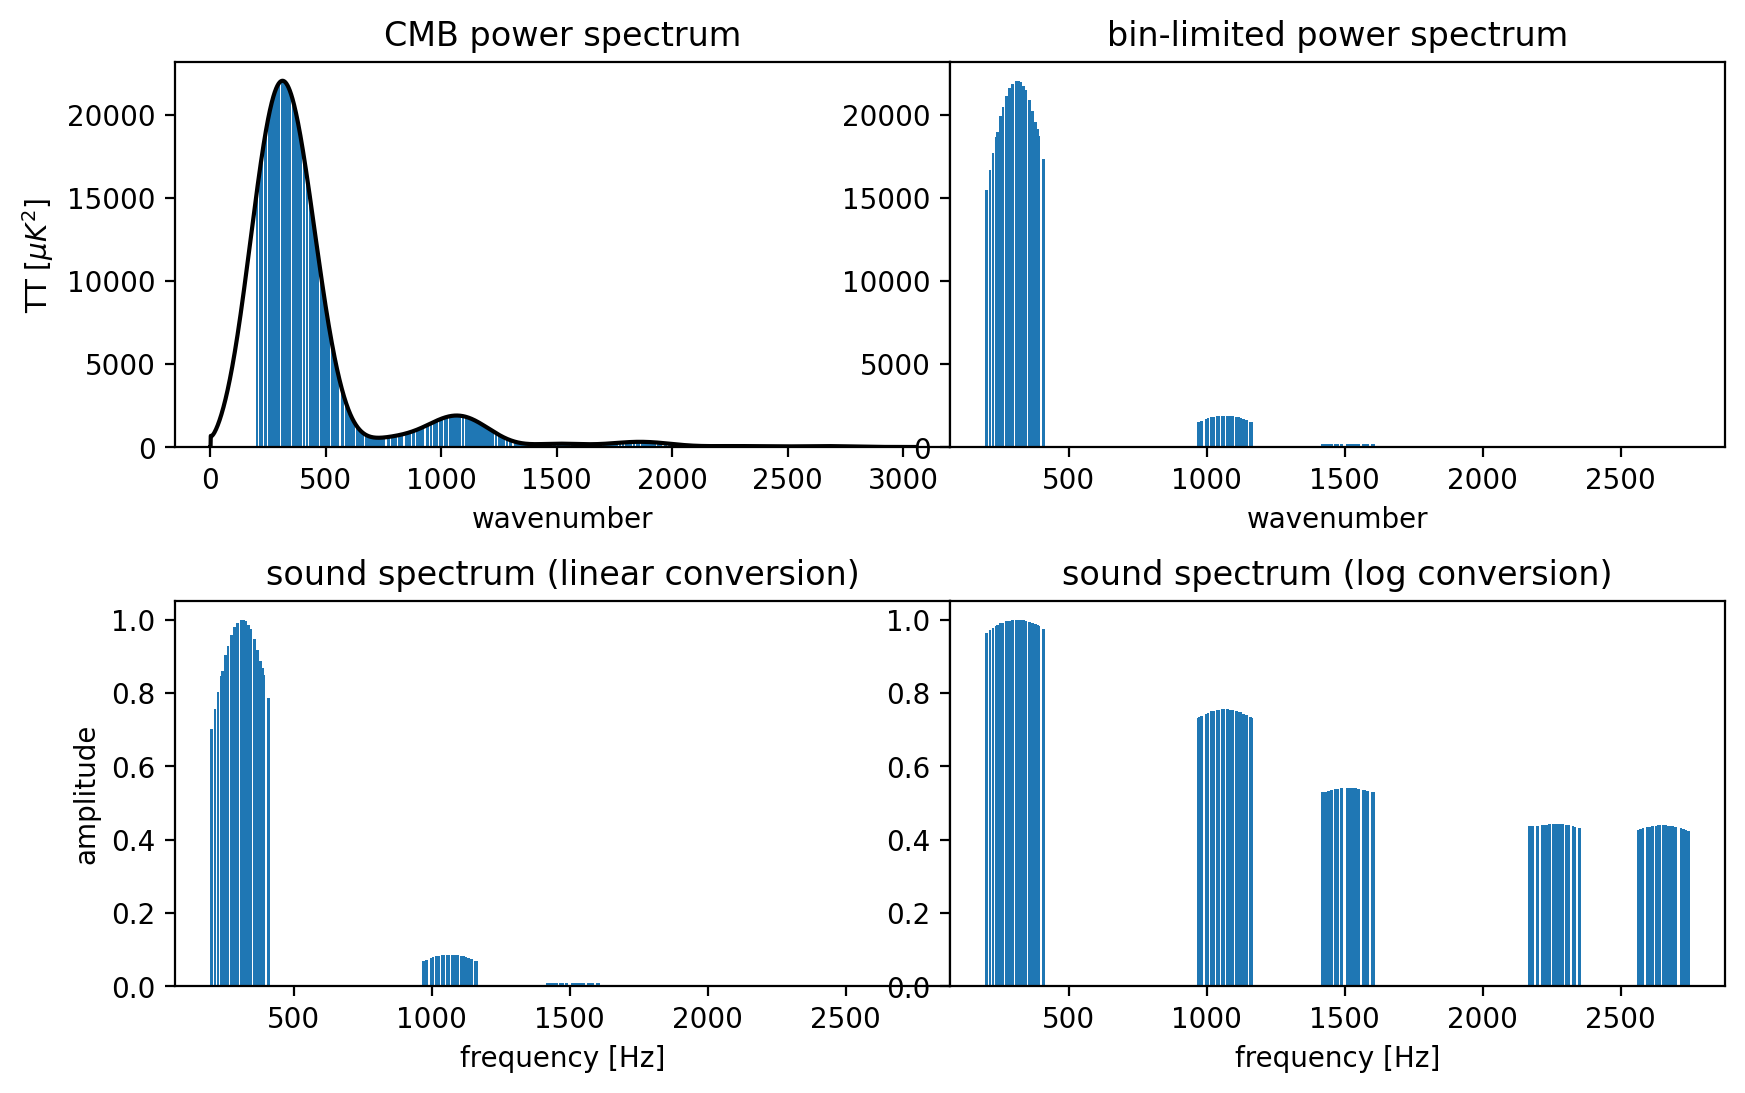

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

fig.subplots_adjust(hspace=0.4, wspace=0)

ax[0][0].plot(ls, dat, color='k')
ax[0][0].bar(freqbins, binned, width=10)

for a in ax[0]:
    a.set_xlabel('wavenumber')
    
ax[0][0].set_ylabel('TT [$\mu K^2$]')
ax[0][0].set_title('CMB power spectrum')
ax[0][1].set_title('bin-limited power spectrum')

ax[0][1].bar(lim_x, lim_dat, width=10)

ax[1][0].bar(freq, amplin, width=binsize)
ax[1][1].bar(freq, amplog, width=binsize)
ax[1][0].set_title('sound spectrum (linear conversion)')
ax[1][1].set_title('sound spectrum (log conversion)')

for a in ax[1]:
    a.set_xlabel('frequency [Hz]')
ax[1][0].set_ylabel('amplitude')

# Massage into Max-readable Data

In [17]:
#test for 2x2: omL = 0.685, 0.1 with equal calc, bin_num = 5, 10
ps_models = {0:{'omL':0.685, 'calc':'equal'}, 1:{'omL': 0.1, 'calc':'equal'}}

In [18]:
ps_models = {}

for i in range(47):
    ps_models[i] = {'omL': 0.02*(i+1), 'calc':'equal' }

In [19]:
ps_models = {}

for i in range(10):
    ps_models[i] = {'omL': 0.685, 'calc': 10-i}

for i in range(10):
    ps_models[i+10] = {'omL': 0.685, 'calc': 1/(i+1)}

for i in range(47):
    ps_models[i+20] = {'omL': 0.02*(i+1), 'calc':'equal' }

In [20]:
ps_models

{0: {'omL': 0.685, 'calc': 10},
 1: {'omL': 0.685, 'calc': 9},
 2: {'omL': 0.685, 'calc': 8},
 3: {'omL': 0.685, 'calc': 7},
 4: {'omL': 0.685, 'calc': 6},
 5: {'omL': 0.685, 'calc': 5},
 6: {'omL': 0.685, 'calc': 4},
 7: {'omL': 0.685, 'calc': 3},
 8: {'omL': 0.685, 'calc': 2},
 9: {'omL': 0.685, 'calc': 1},
 10: {'omL': 0.685, 'calc': 1.0},
 11: {'omL': 0.685, 'calc': 0.5},
 12: {'omL': 0.685, 'calc': 0.3333333333333333},
 13: {'omL': 0.685, 'calc': 0.25},
 14: {'omL': 0.685, 'calc': 0.2},
 15: {'omL': 0.685, 'calc': 0.16666666666666666},
 16: {'omL': 0.685, 'calc': 0.14285714285714285},
 17: {'omL': 0.685, 'calc': 0.125},
 18: {'omL': 0.685, 'calc': 0.1111111111111111},
 19: {'omL': 0.685, 'calc': 0.1},
 20: {'omL': 0.02, 'calc': 'equal'},
 21: {'omL': 0.04, 'calc': 'equal'},
 22: {'omL': 0.06, 'calc': 'equal'},
 23: {'omL': 0.08, 'calc': 'equal'},
 24: {'omL': 0.1, 'calc': 'equal'},
 25: {'omL': 0.12, 'calc': 'equal'},
 26: {'omL': 0.14, 'calc': 'equal'},
 27: {'omL': 0.16, 'calc':

In [21]:
bin_nums = {}

for i in range(87):
    bin_nums[(i+1)*10] = 20+i*3

In [22]:
bin_nums

{10: 20,
 20: 23,
 30: 26,
 40: 29,
 50: 32,
 60: 35,
 70: 38,
 80: 41,
 90: 44,
 100: 47,
 110: 50,
 120: 53,
 130: 56,
 140: 59,
 150: 62,
 160: 65,
 170: 68,
 180: 71,
 190: 74,
 200: 77,
 210: 80,
 220: 83,
 230: 86,
 240: 89,
 250: 92,
 260: 95,
 270: 98,
 280: 101,
 290: 104,
 300: 107,
 310: 110,
 320: 113,
 330: 116,
 340: 119,
 350: 122,
 360: 125,
 370: 128,
 380: 131,
 390: 134,
 400: 137,
 410: 140,
 420: 143,
 430: 146,
 440: 149,
 450: 152,
 460: 155,
 470: 158,
 480: 161,
 490: 164,
 500: 167,
 510: 170,
 520: 173,
 530: 176,
 540: 179,
 550: 182,
 560: 185,
 570: 188,
 580: 191,
 590: 194,
 600: 197,
 610: 200,
 620: 203,
 630: 206,
 640: 209,
 650: 212,
 660: 215,
 670: 218,
 680: 221,
 690: 224,
 700: 227,
 710: 230,
 720: 233,
 730: 236,
 740: 239,
 750: 242,
 760: 245,
 770: 248,
 780: 251,
 790: 254,
 800: 257,
 810: 260,
 820: 263,
 830: 266,
 840: 269,
 850: 272,
 860: 275,
 870: 278}

In [23]:
from collections import defaultdict

In [24]:
#data for each omLval
#index by [model_ind]
xvals = {}
ps_data = {}
binned_data = {}

#data per each bin setting 
#index by [model_ind][bin_num_ind]
lim_xvals = defaultdict(dict)
lim_data = defaultdict(dict)

freqs = defaultdict(dict)
amps_lin = defaultdict(dict)
amps_log = defaultdict(dict)

amps_lin_unfill = defaultdict(dict)
amps_log_unfill = defaultdict(dict)

In [25]:
#build models & get data and binned
for Mind in ps_models.keys():
    
    model = ps_models[Mind]
    
    ls, dat = get_data(omL = model['omL'], calc=model['calc'], verbose=True)
    binned = bin_data(ls, dat)
    
    xvals[Mind] = ls
    ps_data[Mind] = dat
    binned_data[Mind] = binned

omc= 0.2851 omb= 0.0285
balance 0.3136 0.3136
omc= 0.2822 omb= 0.0314
balance 0.3136 0.3136
omc= 0.2787 omb= 0.0348
balance 0.3136 0.3136
omc= 0.2744 omb= 0.0392
balance 0.3136 0.3136
omc= 0.2688 omb= 0.0448
balance 0.3136 0.3136
omc= 0.2613 omb= 0.0523
balance 0.3136 0.3136
omc= 0.2509 omb= 0.0627
balance 0.3136 0.3136
omc= 0.2352 omb= 0.0784
balance 0.3136 0.3136
omc= 0.2091 omb= 0.1045
balance 0.3136 0.3136
omc= 0.1568 omb= 0.1568
balance 0.3136 0.3136
omc= 0.1568 omb= 0.1568
balance 0.3136 0.3136
omc= 0.1045 omb= 0.2091
balance 0.3136 0.3136
omc= 0.0784 omb= 0.2352
balance 0.3136 0.3136
omc= 0.0627 omb= 0.2509
balance 0.3136 0.3136
omc= 0.0523 omb= 0.2613
balance 0.3136 0.3136
omc= 0.0448 omb= 0.2688
balance 0.3136 0.3136
omc= 0.0392 omb= 0.2744
balance 0.3136 0.3136
omc= 0.0348 omb= 0.2787
balance 0.3136 0.3136
omc= 0.0314 omb= 0.2822
balance 0.3136 0.3136
omc= 0.0285 omb= 0.2851
balance 0.3136 0.3136
omc= 0.4893 omb= 0.4893
balance 0.9786 0.9786
omc= 0.4793 omb= 0.4793
balance 0.

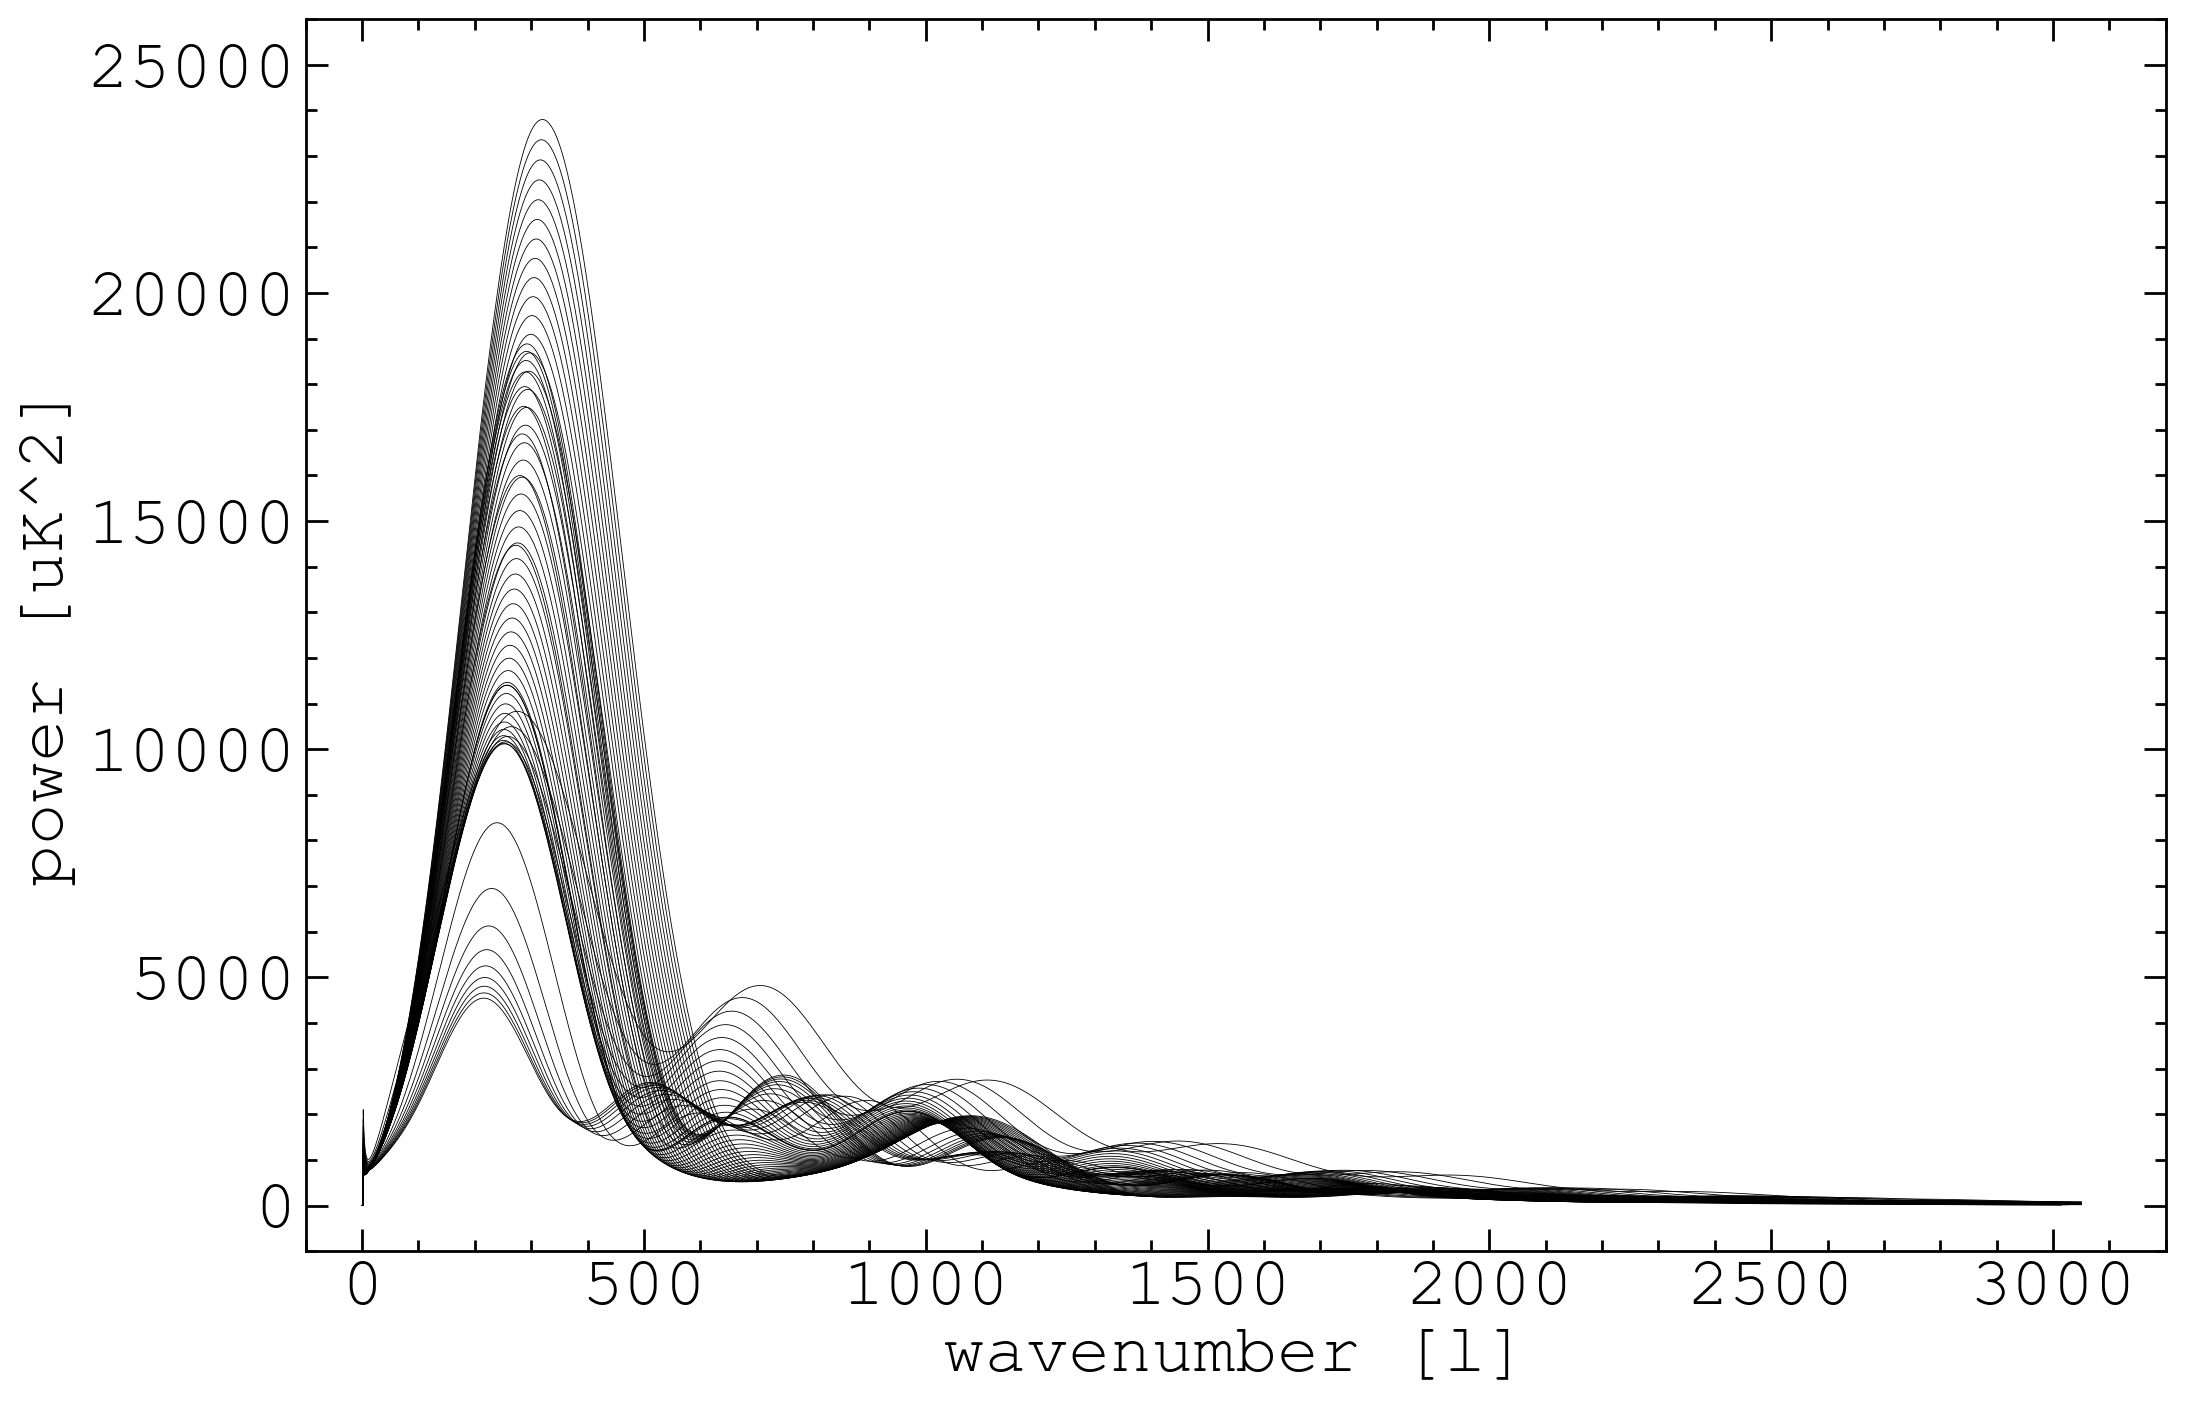

In [83]:
plt.figure(figsize=(12, 8))
plt.style.use('grayscale')
for Mind in ps_models.keys():
    plt.plot(xvals[Mind], ps_data[Mind], label=str(Mind), linewidth=0.3, color='k')

#plt.plot(xvals[Mind], ps_data[Mind], c='k', linewidth=5)
#plt.legend()
plt.ylabel('power [uK^2]', fontname='Courier New', fontsize=25)
plt.xlabel('wavenumber [l]', fontname='Courier New', fontsize=25)

plt.tick_params(which='minor', direction="in", width=1, size=4)
plt.tick_params(which='major', direction="in", width=1, size=8)
plt.tick_params(top='true', which='minor')
plt.tick_params(top='true', which='major')
plt.tick_params(right='true', which='minor')
plt.tick_params(right='true', which='major')
plt.minorticks_on()

plt.xlim(-100, 3200)
plt.ylim(-1000, 26000)

plt.xticks(fontname='Courier New', fontsize=25)
plt.yticks(fontname='Courier New', fontsize=25)

plt.rcParams['axes.linewidth'] = 1
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'

plt.savefig('cmbmodels.png', dpi=300, bbox_inches='tight', transparent=True)

In [653]:
#set each binlim for each model
for Mind in ps_models.keys():
    for Bind in bin_nums.keys():

        ls = xvals[Mind]
        dat = ps_data[Mind]
        binned = binned_data[Mind]
        bin_num = bin_nums[Bind]

        lim_x, lim_dat = limit_bins(binned, dat, bin_lim = bin_num)

        lim_xvals[Mind][Bind] = lim_x
        lim_data[Mind][Bind] = lim_dat

In [654]:
#get datamax out of all models
datamax = 0
for Mind in ps_models.keys():
    max = np.max(ps_data[Mind])
    if max > datamax:
        datamax = max

In [655]:
def fill_zerofreqs(freqs, amps):
    #for unrepresented frequencies, fill w/ zero amplitude 
    newamps = []
    for f in freqbins: 
        if f in freqs:
            ind = freqs.index(f)
            amp = amps[ind]
            newamps.append(amp)
        else:
            newamps.append(0)
    return newamps

In [656]:
#get freqs and amps for each model 
for Mind in ps_models.keys():
    for Bind in bin_nums.keys():

        lim_x = lim_xvals[Mind][Bind]
        lim_dat = lim_data[Mind][Bind]

        freq, amplin = convert_to_ampfreq(lim_x, lim_dat, mode='linear', datamax=datamax)
        
        freq, amplog = convert_to_ampfreq(lim_x, lim_dat, mode='log', datamax=datamax)

        amps_lin_unfill[Mind][Bind] = amplin
        amps_log_unfill[Mind][Bind] = amplog

        amplin = fill_zerofreqs(freq, amplin)
        amplog = fill_zerofreqs(freq, amplog)

        freqs[Mind][Bind] = freq
        amps_lin[Mind][Bind] = amplin
        amps_log[Mind][Bind] = amplog

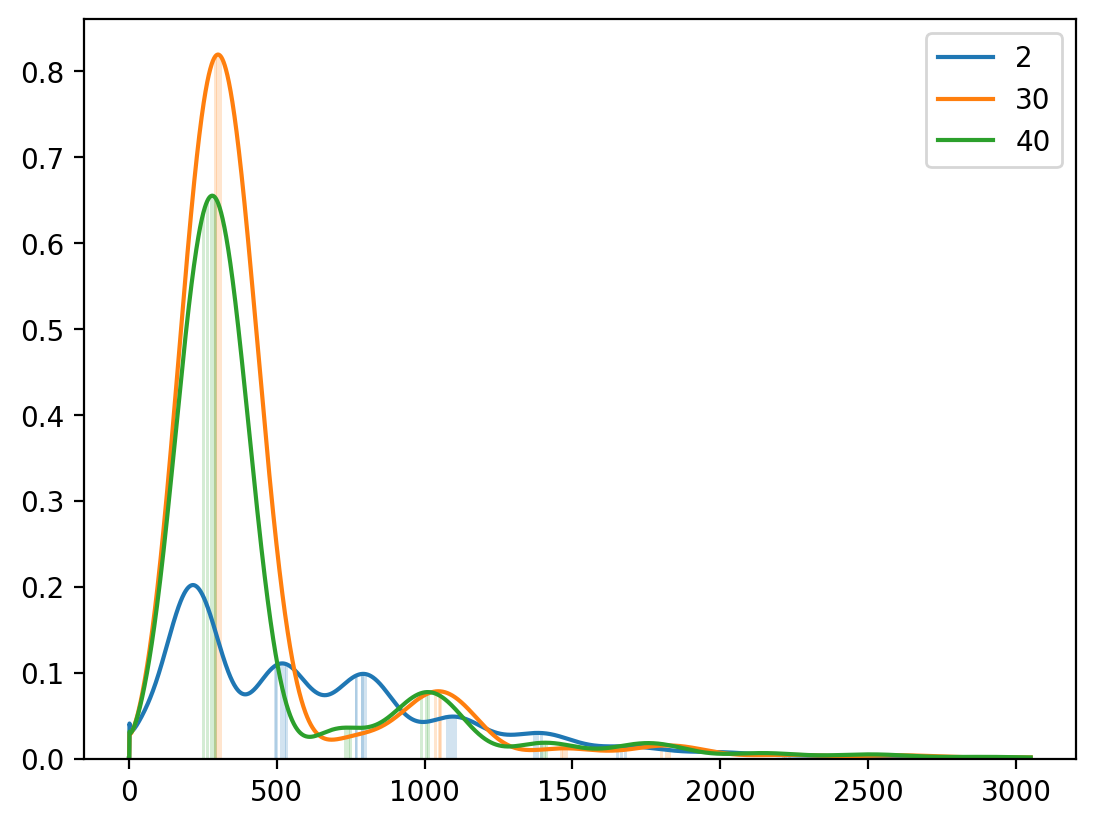

In [657]:
Bind = 10
for Mind in [2, 30, 40]:
    plt.bar(freqbins, amps_lin[Mind][Bind], width=10, alpha=0.2)
    plt.plot(xvals[Mind], ps_data[Mind]/datamax, label=str(Mind))
plt.legend()

In [658]:
#CONVERT! 
def convert_to_text(amp_dat, ps_models, bin_nums):
    #frequency data
    #amplitude data
    #convert into max-readable format
    #one line per model
    #Mind, Bind amp amp amp amp Bind amp amp amp amp Bind amp amp amp amp 
    
    lines = {}
    for Mind in ps_models.keys():
        line = str(Mind) + ", "

        for Bind in bin_nums.keys():
            line += str(Bind) + " "

            for a in amp_dat[Mind][Bind]:
                line+= str(a) + " "

        line = line[:-1] + ';'
        lines[Mind] = line
    return lines

In [659]:
l = convert_to_text(amps_lin, ps_models, bin_nums)

In [660]:
len(l[0].split(' '))

24448

In [661]:
l[0][286]

'4'

In [662]:
len(freqbins)

280

In [663]:
with open('test_values.txt', 'w') as f:
    for line in l.values():
        f.write(line+'\n')

In [500]:
for x in freqbins:
    print(str(x) + " ", end="")

202 212 226 233 243 252 265 279 289 292 301 311 321 336 341 354 363 376 380 391 402 410 429 430 442 458 461 475 481 497 500 517 526 534 544 555 569 570 582 590 608 613 626 638 648 652 666 677 682 692 707 715 729 732 744 751 768 771 789 791 801 818 820 835 843 859 862 875 886 898 903 912 924 933 949 957 966 972 986 991 1006 1014 1026 1036 1049 1055 1069 1078 1086 1094 1104 1113 1128 1134 1140 1150 1161 1173 1184 1193 1206 1215 1223 1238 1240 1256 1263 1275 1284 1297 1303 1311 1323 1339 1340 1358 1362 1373 1382 1397 1406 1411 1428 1433 1442 1455 1464 1471 1480 1497 1505 1513 1525 1534 1548 1554 1569 1572 1583 1597 1605 1619 1628 1632 1648 1653 1666 1678 1686 1693 1700 1711 1724 1730 1743 1750 1766 1774 1788 1799 1801 1817 1829 1836 1847 1857 1868 1877 1885 1893 1901 1910 1923 1935 1946 1958 1963 1977 1987 1995 2009 2010 2025 2031 2041 2052 2065 2072 2082 2091 2104 2111 2121 2137 2148 2156 2161 2170 2185 2197 2200 2213 2220 2235 2244 2255 2266 2272 2283 2297 2309 2316 2323 2338 2347 2353 

In [665]:
for x in freqbins:
    print(str(0.) + " ", end="")

0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 

# RANDOM WORK

In [10]:
#trying for 5 values of omL, with omc = omb
xvals = []
datas = []
binned_datas = []

for omL in omLvals:
    ls, dat = get_data(omL=omL)
    binned = bin_data(ls, dat)
    xvals.append(ls)
    datas.append(dat)
    binned_datas.append(binned)

In [45]:
lim_xvals, lim_data = limit_bins(binned_datas[0], datas[0], bin_lim = 100)

In [55]:
freq, amp = convert_to_ampfreq(lim_xvals, lim_data, mode='log')

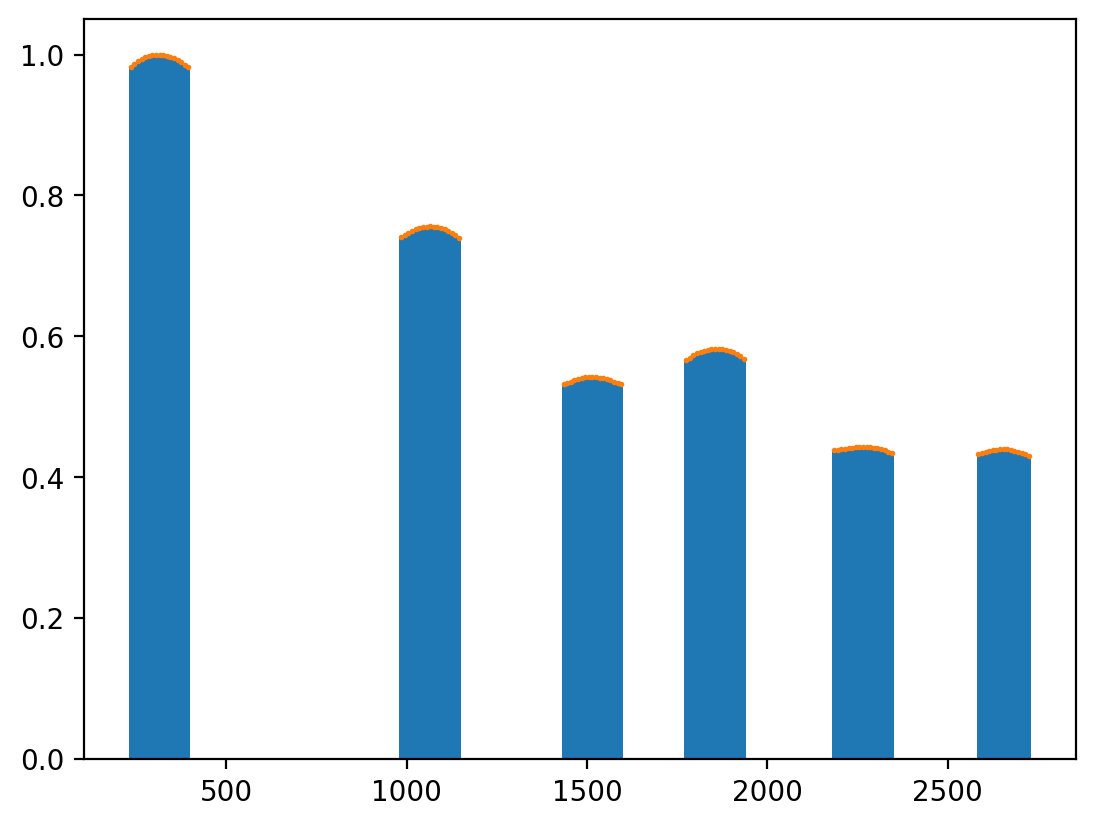

In [56]:
plt.bar(freq, amp, width=binsize)
plt.scatter(freq, amp, s=1)

<BarContainer object of 100 artists>

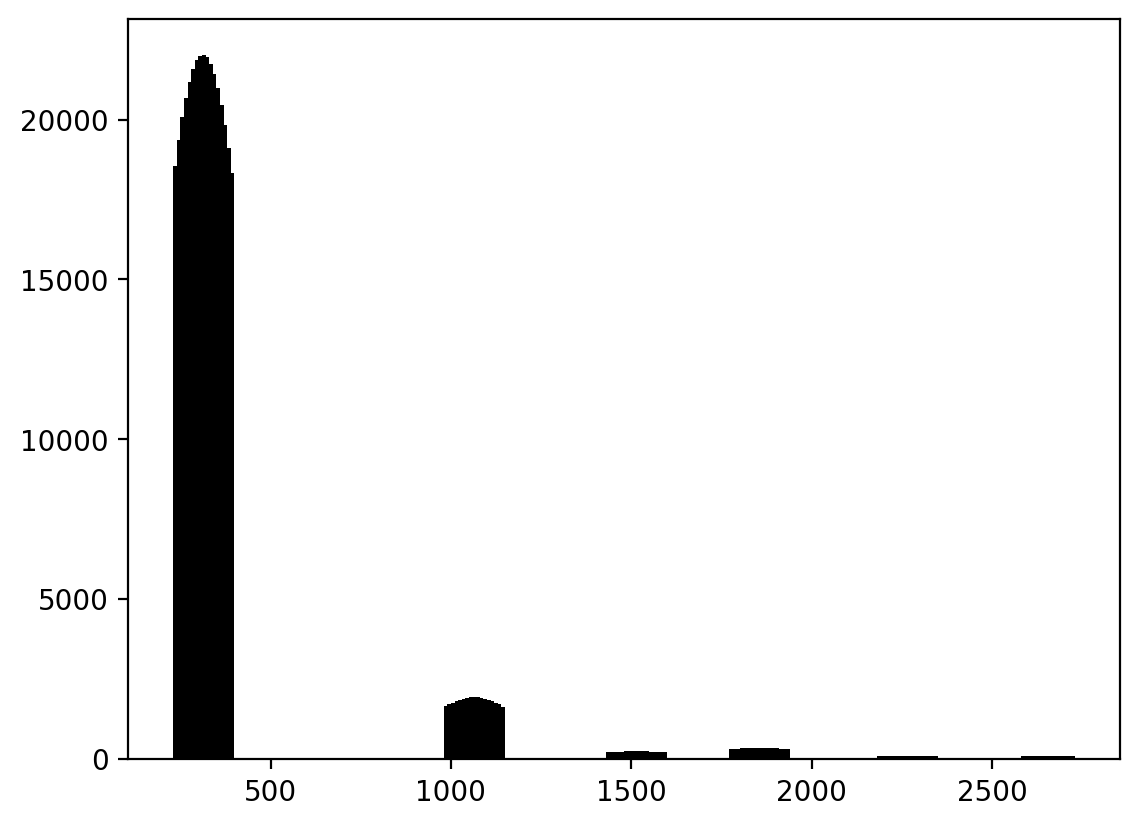

In [46]:
#plt.plot(xvals[0], datas[0])
#plt.plot(peaks, datas[0][peaks], 'x')
plt.bar(lim_xvals, lim_data, width=binsize, color='k')

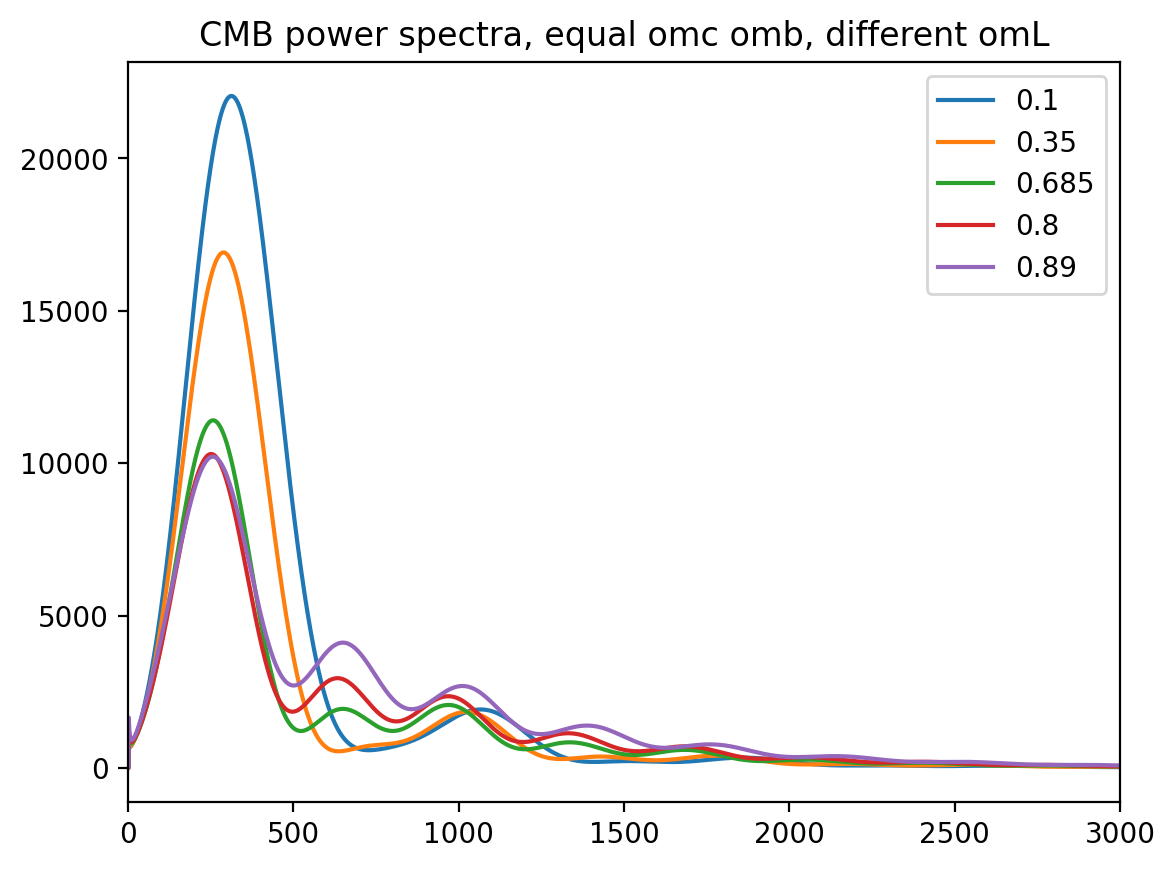

In [11]:
for i in range(len(omLvals)):
    omL = omLvals[i]
    ls = xvals[i]
    dat = datas[i]
    plt.plot(ls, dat, label=omL)
    #plt.xscale('log')
    plt.xlim(0, 3000)
    #plt.yscale('log')
    plt.legend()
    plt.title("CMB power spectra, equal omc omb, different omL")

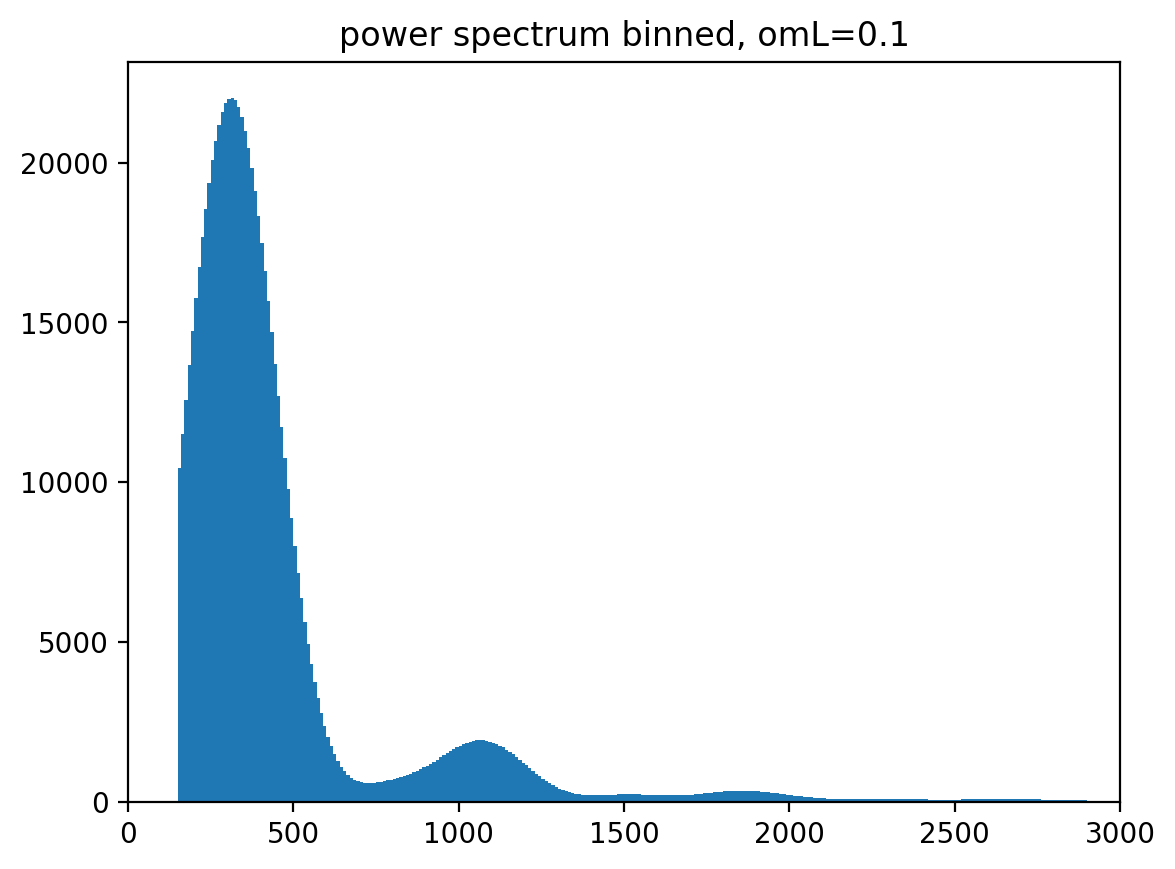

In [12]:
for i in range(1):
    omL = omLvals[i]
    ls = xvals[i]
    dat = datas[i]
    binned = binned_datas[i]
    plt.bar(freqbins, binned, width=binsize)
    #plt.plot(ls, dat, color='k')
    #plt.xscale('log')
    plt.xlim(0, 3000)
    #plt.yscale('log')
    plt.title("power spectrum binned, omL=0.1")